[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HisameOgasahara/tml_p1_rl/blob/main/02_stage2_conditions.ipynb)

# 2단계. 적용 조건 — 전제·실패 신호, 대안 비교

**런타임: CPU.** 1단계 노트북과 같은 런타임이면 `results/`, `base.pt` 캐시를 재사용합니다.

In [1]:
import os, sys, time, dataclasses
if not os.path.exists("fg8.py"):
    !git clone -q https://github.com/HisameOgasahara/tml_p1_rl.git
    %cd tml_p1_rl
import numpy as np, torch, matplotlib.pyplot as plt
import fg8
torch.set_num_threads(os.cpu_count())
print("torch", torch.__version__, "| threads", torch.get_num_threads())
base = fg8.get_base()          # 처음 한 번 RF 사전학습(~1분), 이후 base.pt 재사용

/content/tml_p1_rl
torch 2.11.0+cpu | threads 2
  base step     0  loss 2.9741
  base step  1000  loss 1.8248
  base step  2000  loss 1.7737
  base step  3000  loss 1.8287
  base step  4000  loss 1.7953
  base step  5000  loss 1.7177
  base step  6000  loss 1.9080
  base step  7000  loss 1.7813


In [2]:
SEEDS = [0, 1, 2]

def run_all(cfgs):
    out = {}
    for name, c in cfgs.items():
        t0 = time.time()
        out[name] = [fg8.run(base, dataclasses.replace(c, seed=s), name, verbose=(s == 0)) for s in SEEDS]
        print(f"{name}: {time.time() - t0:.0f}s")
    return out

def final(runs, key):
    return np.array([r["ode"][-1][key] for r in runs])

def table(runs_by_name, keys=("reward", "target_mass", "off_support", "within_std")):
    print(f"{'run':<16}" + "".join(f"{k:>16}" for k in keys) + f"{'train s':>10}{'NFE':>12}")
    base_m = next(iter(runs_by_name.values()))[0]["ode"][0]
    print(f"{'base':<16}" + "".join(f"{base_m[k]:>16.4f}" for k in keys))
    for name, runs in runs_by_name.items():
        cells = "".join(f"{final(runs, k).mean():>9.4f}±{final(runs, k).std():<6.4f}" for k in keys)
        print(f"{name:<16}{cells}{np.mean([r['time'][-1] for r in runs]):>10.1f}{runs[0]['nfe'][-1]:>12,}")

def curves(runs_by_name, x="it", key="reward", ax=None, ylim=None, start=0, label=None):
    """key: metric name or a function of the eval dict; non-finite values are dropped; start: first iteration"""
    ax = ax or plt.gca()
    get = key if callable(key) else (lambda m: m[key])
    for name, runs in runs_by_name.items():
        keep = np.array(runs[0]["it"]) >= start
        xs = np.array(runs[0][x])[keep]
        ys = np.array([[get(m) for m in r["ode"]] for r in runs], dtype=float)[:, keep]
        ys[~np.isfinite(ys)] = np.nan
        ax.plot(xs, np.nanmean(ys, 0), label=name)
        ax.fill_between(xs, np.nanmin(ys, 0), np.nanmax(ys, 0), alpha=0.2)
    ax.set_xlabel(x); ax.set_ylabel(f"ODE {label or key}"); ax.legend()
    if ylim: ax.set_ylim(*ylim)

def scatter(ax, pts, title):
    pts = np.asarray(pts); ax.scatter(pts[:, 0], pts[:, 1], s=2, zorder=2)
    m = fg8.MODES.numpy()   # hollow target markers behind the points, so a collapsed cluster stays visible
    ax.scatter(m[list(fg8.TARGET), 0], m[list(fg8.TARGET), 1], s=120, facecolors="none", edgecolors="r", zorder=1)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.set_title(title)

## 2-① 언제 이식 가능한가 — 전제, 실패, 신호 (§8, A.3, Q24)

| 전제 | 신호 |
|---|---|
| 그룹 안 보상에 분산이 있다 | std=0 그룹 비율 ≈ p^G + (1-p)^G, 보상 정체 |
| 학습 SDE와 평가 ODE 분포가 같다 | 같은 policy의 SDE(T=10) vs ODE(T=40) reward 차이 |
| clip이 모든 t에서 작동한다 | t 구간별 clip 비율 (GRPO-Guard) |
| 보상 상승 = 품질 상승 | reward ↑ 동시에 off-support ↑ / within-std ↓ |

  [flow_grpo] it    0  ode reward -2.0398  target mass 0.247  off-support 0.042  within-std 0.091
  [flow_grpo] it   20  ode reward -0.0664  target mass 0.999  off-support 0.008  within-std 0.051
  [flow_grpo] it   40  ode reward -0.0324  target mass 0.999  off-support 0.002  within-std 0.026
  [flow_grpo] it   60  ode reward -0.0273  target mass 1.000  off-support 0.002  within-std 0.022
  [flow_grpo] it   80  ode reward -0.0250  target mass 1.000  off-support 0.001  within-std 0.022
  [flow_grpo] it  100  ode reward -0.0274  target mass 1.000  off-support 0.002  within-std 0.023
  [flow_grpo] it  120  ode reward -0.0308  target mass 1.000  off-support 0.001  within-std 0.027
  [flow_grpo] it  140  ode reward -0.0358  target mass 1.000  off-support 0.001  within-std 0.030
  [flow_grpo] it  160  ode reward -0.0386  target mass 1.000  off-support 0.001  within-std 0.031
  [flow_grpo] it  180  ode reward -0.0441  target mass 1.000  off-support 0.002  within-std 0.036
  [flow_grpo] it  20

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


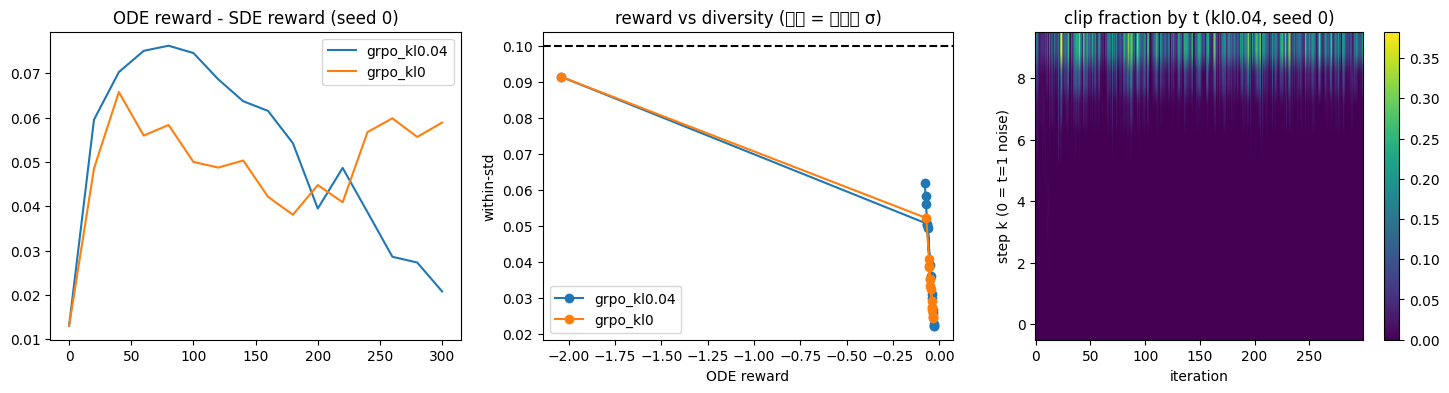

In [3]:
dense = run_all({"grpo_kl0.04": fg8.Cfg(), "grpo_kl0": fg8.Cfg(beta_kl=0.0)})
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for name, rs in dense.items():
    r = rs[0]
    ax[0].plot(r["it"], [m["reward"] - s for m, s in zip(r["ode"], r["sde_reward"])], label=name)
ax[0].set_title("ODE reward - SDE reward (seed 0)"); ax[0].legend()
for name, rs in dense.items():
    r = rs[0]
    ev = [m for i, m in zip(r["it"], r["ode"]) if i >= 20]      # skip iter 0 (base, reward -2.04)
    ax[1].plot([m["reward"] for m in ev], [m["within_std"] for m in ev], "o-", label=name)
ax[1].axhline(fg8.SIGMA, ls="--", c="k"); ax[1].set_xlabel("ODE reward"); ax[1].set_ylabel("within-std"); ax[1].legend()
ax[1].set_title("reward vs diversity, iter >= 20 (dashed = data sigma)")
im = ax[2].imshow(np.array(dense["grpo_kl0.04"][0]["clip_by_t"]).T, aspect="auto", origin="lower")
ax[2].set_xlabel("iteration"); ax[2].set_ylabel("step k (0 = t=1 noise)"); ax[2].set_title("clip fraction by t (kl0.04, seed 0)")
plt.colorbar(im, ax=ax[2]); plt.show()

### 그룹 분산 전제를 깨기: 희소 보상 (mode 0 반경 σ 안이면 1)

먼저 base에서 std=0 그룹 비율이 이론값 p^G + (1-p)^G와 맞는지 확인하고, 총 샘플 수(batch=384)를 고정한 채 G=4 vs G=24로 학습합니다.

PASS zero-std theory: {'p': 0.04242708161473274, 4: {'measured': 0.8409166932106018, 'theory': 0.8407930127752011}, 24: {'measured': 0.3487499952316284, 'theory': 0.35328444952015775}}
  [flow_grpo] it    0  ode reward +0.0570  target mass 0.247  off-support 0.042  within-std 0.091
  [flow_grpo] it   20  ode reward +0.9240  target mass 0.959  off-support 0.012  within-std 0.040
  [flow_grpo] it   40  ode reward +0.9910  target mass 0.998  off-support 0.002  within-std 0.023
  [flow_grpo] it   60  ode reward +0.9942  target mass 0.999  off-support 0.001  within-std 0.021
  [flow_grpo] it   80  ode reward +0.9923  target mass 0.999  off-support 0.001  within-std 0.029
  [flow_grpo] it  100  ode reward +0.9927  target mass 0.999  off-support 0.001  within-std 0.027
  [flow_grpo] it  120  ode reward +0.9900  target mass 1.000  off-support 0.001  within-std 0.027
  [flow_grpo] it  140  ode reward +0.9895  target mass 0.999  off-support 0.001  within-std 0.026
  [flow_grpo] it  160  ode rewa

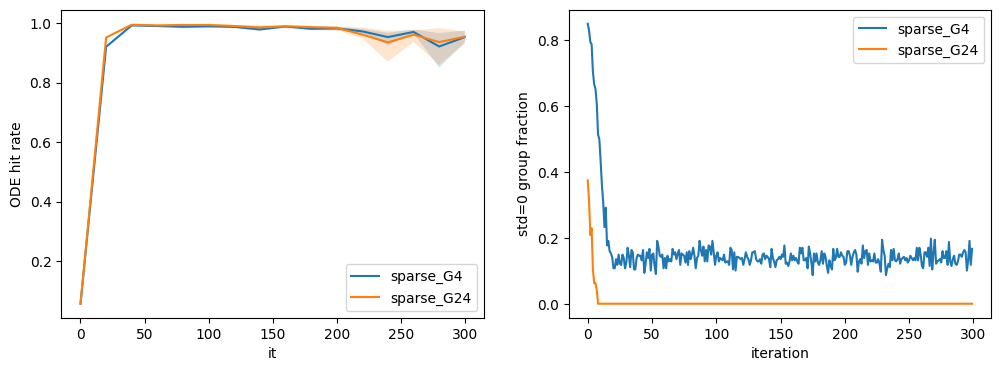

In [4]:
zs = fg8.check_zero_std(base)
print("PASS zero-std theory:", zs)
sparse = run_all({
    "sparse_G4":  fg8.Cfg(reward="sparse", G=4),
    "sparse_G24": fg8.Cfg(reward="sparse", G=24),
})
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
curves(sparse, key="reward", ax=ax[0]); ax[0].set_ylabel("ODE hit rate")
for name, rs in sparse.items():
    ax[1].plot(np.mean([r["zero_std"] for r in rs], 0), label=name)
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("std=0 group fraction"); ax[1].legend()
plt.show()

## 2-② 대안 중 언제 고르고 언제 피하나

같은 base·보상·iteration당 샘플 수(384)로 비교.

- **(a) PPO**: SDE rollout·ratio·clip·KL은 Flow-GRPO와 동일, advantage만 critic V(x_t, t)로. 2D에서는 critic 학습이 쉬워 PPO에 유리할 수 있음.
- **(b) DGPO, DiffusionNFT**: 튜토리얼 Q25 기준(정답) — SDE 비용을 낼 수 있고 스텝별 likelihood가 필요하면 Flow-GRPO, ODE만 쓰거나 저장·속도가 중요하면 DGPO/NFT. toy 결과가 이 기준과 맞는지 확인.
- DGPO `dgpo_beta_T`, NFT `nft_beta`는 손실 스케일 규약에 묶인 값(§4.8, §5.7)이라 toy에서 조정이 필요할 수 있음.

In [5]:
alts = run_all({
    "grpo_kl0.04": fg8.Cfg(),
    "ppo":        fg8.Cfg(algo="ppo"),
    "dgpo":       fg8.Cfg(algo="dgpo"),
    "nft":        fg8.Cfg(algo="nft"),
})
ppo_sparse = run_all({"ppo_sparse": fg8.Cfg(algo="ppo", reward="sparse")})

grpo_kl0.04: 0s
  [ppo] it    0  ode reward -2.0398  target mass 0.247  off-support 0.042  within-std 0.091
  [ppo] it   20  ode reward -0.0682  target mass 1.000  off-support 0.006  within-std 0.053
  [ppo] it   40  ode reward -0.0220  target mass 1.000  off-support 0.002  within-std 0.019
  [ppo] it   60  ode reward -0.0277  target mass 1.000  off-support 0.000  within-std 0.023
  [ppo] it   80  ode reward -0.0259  target mass 1.000  off-support 0.001  within-std 0.021
  [ppo] it  100  ode reward -0.0297  target mass 1.000  off-support 0.001  within-std 0.026
  [ppo] it  120  ode reward -0.0383  target mass 1.000  off-support 0.000  within-std 0.031
  [ppo] it  140  ode reward -0.0454  target mass 1.000  off-support 0.000  within-std 0.036
  [ppo] it  160  ode reward -0.0381  target mass 1.000  off-support 0.000  within-std 0.031
  [ppo] it  180  ode reward -0.0437  target mass 1.000  off-support 0.000  within-std 0.036
  [ppo] it  200  ode reward -0.0437  target mass 1.000  off-supp

run                       reward     target_mass     off_support      within_std   train s         NFE
base                     -2.0398          0.2472          0.0420          0.0913
grpo_kl0.04       -0.0770±0.0122   1.0000±0.0000   0.0003±0.0002   0.0599±0.0094      85.2   3,456,000
ppo               -0.0822±0.0220   1.0000±0.0000   0.0002±0.0001   0.0643±0.0180     133.5   5,760,000
dgpo              -0.1570±0.0313   0.9991±0.0007   0.0080±0.0023   0.1105±0.0214      64.7   2,995,200
nft                  -inf±nan      1.0000±0.0000   0.1428±0.0301   0.0556±0.0144      43.5   2,995,200

grpo_kl0.04 rollout buffer floats: 12,288
ppo    rollout buffer floats: 12,288
dgpo   rollout buffer floats: 1,152
nft    rollout buffer floats: 1,152


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:194: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


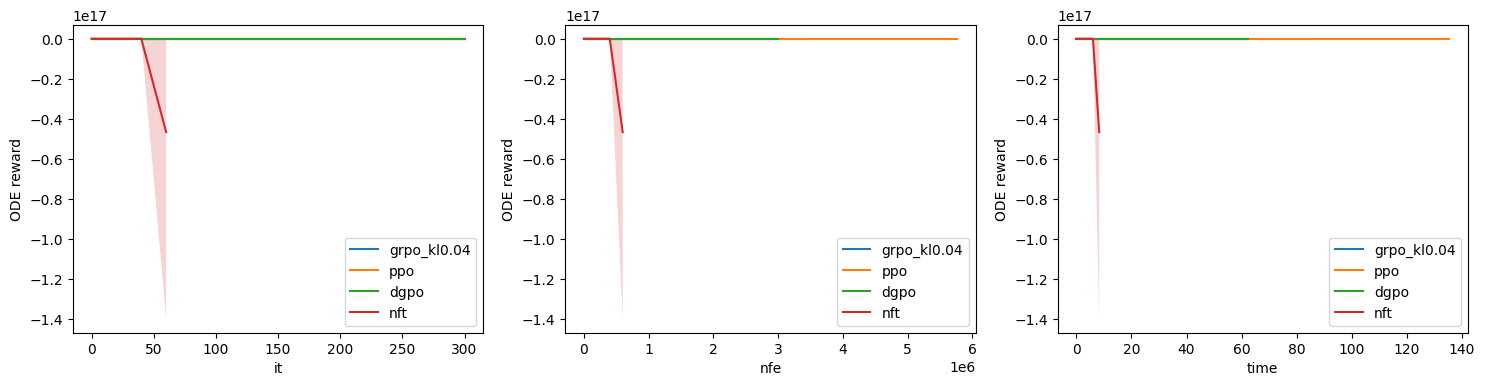

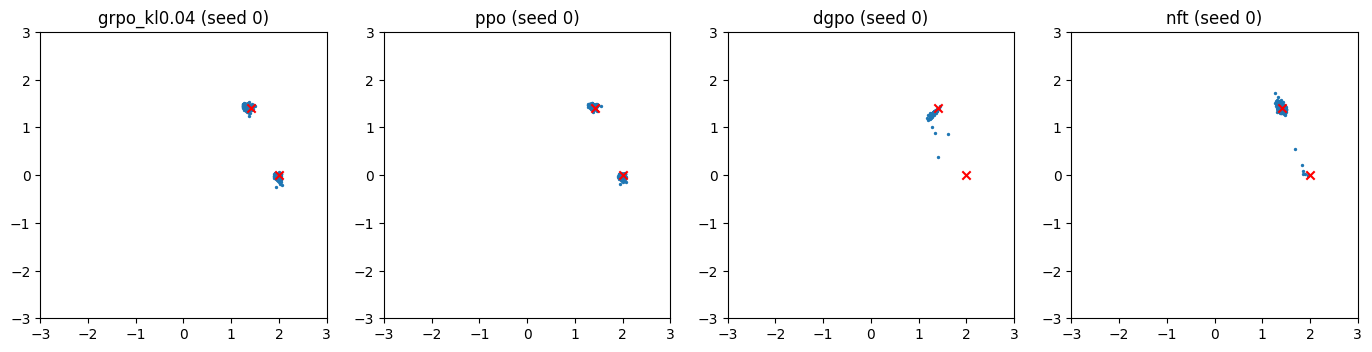

sparse reward: Flow-GRPO G=4 / G=24 vs PPO
run                       reward   train s         NFE
base                      0.0570
sparse_G4          0.9533±0.0167      83.1   3,456,000
sparse_G24         0.9546±0.0172      84.7   3,456,000
ppo_sparse         0.9437±0.0355     131.1   5,760,000


In [6]:
table(alts)
print()
for name, rs in alts.items():
    print(f"{name:<6} rollout buffer floats: {rs[0]['buffer_floats']:,}")
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
# NFT diverges to -1e17: non-finite values dropped, y clipped to [-0.5, 0]
for a_, x in zip(ax, ("it", "nfe", "time")):
    curves(alts, x=x, ax=a_, ylim=(-0.5, 0))
plt.show()
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a_, (name, rs) in zip(ax, alts.items()):
    scatter(a_, rs[0]["final_samples"], f"{name} (seed 0)")
plt.show()
print("sparse reward: Flow-GRPO G=4 / G=24 vs PPO")
table({**sparse, **ppo_sparse}, keys=("reward",))

### DGPO / NFT 후보 설정 (기본값에서 불안정했던 두 방법)

규칙: 후보는 실행 전에 아래로 고정하고, 더 늘리지 않는다. 각 후보 3시드, 다른 설정은 2-②와 동일.

- **통과** = 3시드 모두 학습 내내 유한하고, 최종 ODE reward ≥ −0.1
- 통과 후보가 있으면 그 결과로 2-②(b) 비교에 넣는다. 없으면 "기본값과 후보에서 안 됨"으로 기록하고 끝낸다.

| 방법 | 기본값 | 후보 | 근거 |
|---|---|---|---|
| DGPO | `dgpo_beta_T=1.0` | 0.1, 0.3, 3.0 | 보상이 진동함 → 더 작게 2개, 반대 방향 1개 |
| NFT | `nft_ema=0.5`, `nft_beta=1.0` | ema 0.9 / ema 0.99 / ema 0.9 + β 2.0 | §8·A.3: old EMA가 policy를 바짝 따라가거나 β가 작으면 불안정 |


In [ ]:
cands = run_all({
    "dgpo_bT0.1": fg8.Cfg(algo="dgpo", dgpo_beta_T=0.1),
    "dgpo_bT0.3": fg8.Cfg(algo="dgpo", dgpo_beta_T=0.3),
    "dgpo_bT3":   fg8.Cfg(algo="dgpo", dgpo_beta_T=3.0),
    "nft_ema0.9":       fg8.Cfg(algo="nft", nft_ema=0.9),
    "nft_ema0.99":      fg8.Cfg(algo="nft", nft_ema=0.99),
    "nft_ema0.9_beta2": fg8.Cfg(algo="nft", nft_ema=0.9, nft_beta=2.0),
})

def passes(rs):
    return all(np.isfinite([m["reward"] for m in r["ode"]]).all() and r["ode"][-1]["reward"] >= -0.1 for r in rs)

def first_hit(rs, thr=-0.1):
    out = []
    for r in rs:
        hit = [(i, t) for i, t, m in zip(r["it"], r["time"], r["ode"]) if m["reward"] >= thr]
        out.append(f"{hit[0][0]}/{hit[0][1]:.0f}s" if hit else "-")
    return out

table({"grpo_kl0.04": alts["grpo_kl0.04"], **cands})
print()
for name, rs in cands.items():
    m01 = [tuple(round(x, 2) for x in r["ode"][-1]["masses"][:2]) for r in rs]
    print(f"{name:<18} {'통과' if passes(rs) else '안 됨':<4}  mode 0/1 {m01}  -0.1 도달 (iter/시간) {first_hit(rs)}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
curves({k: v for k, v in cands.items() if k.startswith("dgpo")}, ax=ax[0], ylim=(-0.5, 0)); ax[0].set_title("DGPO candidates")
curves({k: v for k, v in cands.items() if k.startswith("nft")}, ax=ax[1], ylim=(-0.5, 0)); ax[1].set_title("NFT candidates")
plt.show()
fig, ax = plt.subplots(1, len(cands), figsize=(4.3 * len(cands), 4))
for a_, (name, rs) in zip(ax, cands.items()):
    scatter(a_, rs[0]["final_samples"], f"{name} (seed 0)")
plt.show()


In [7]:
import shutil, os
from google.colab import files

os.makedirs("export2", exist_ok=True)
shutil.copytree("results", "export2/results", dirs_exist_ok=True)
if os.path.exists("base.pt"):
    shutil.copy("base.pt", "export2/base.pt")
shutil.make_archive("stage2_results", "zip", "export2")
files.download("stage2_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>